# Warehouse Hiring → U.S. Online Retail Share
### A falsifiable retrospective macro lead-factor study · 2026-10-27

**Evidence class:** REPRODUCED MACRO PILOT — latest-revised data; historical publication vintages **UNKNOWN**; **not investable equity alpha**.

**Abstract.** Does the excess hiring of U.S. warehousing employees over economy-wide payroll growth forecast a two-quarter increase in the e-commerce share of retail sales? We compare a predeclared lagged signal against historical mean, share persistence, multivariate macro controls, and a signal-only model using 57 purged expanding-window OOS forecasts. We include 1,000 block-aware shuffle refits, 2,000 paired block-bootstrap draws, 1,000 exposure mixtures, multiple horizons, lag shifts, regime splits and leave-one-year-out diagnostics. Data are frozen from an existing official-source snapshot and are not reconstructed historical vintages. **The augmented model fails the historical mean benchmark; any control-relative gain is pandemic-sensitive.**

## 01. Abstract

The unit of analysis is a U.S. calendar quarter, 2000Q1–2026Q3. The target is the **two-quarter change in the Census seasonally adjusted online retail share**, not revenue or stock returns. Our 57 OOS origins run from 2011Q4 to 2025Q4; the training target-availability purge is three quarters. We deliberately retain negative findings and make the fixed-vintage limitation visible.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG
from scipy.stats import spearmanr
from analysis import ROOT, read_raw, make_panel, walk_forward, score, delta, run, ALPHA, PURGE, HORIZON, CONTROLS
from run_analysis import charts
pd.set_option('display.max_columns', 20)
print('Study root:', ROOT)
print('Fixed Ridge alpha:', ALPHA, '| target horizon:', HORIZON, '| purge:', PURGE)

Study root: /mnt/data/retail_research
Fixed Ridge alpha: 8.0 | target horizon: 2 | purge: 3


In [2]:
raw = read_raw()
print('Raw rows:',len(raw),'| Date range:',raw.observation_date.min().date(),'to',raw.observation_date.max().date())
display(raw.head(4))
display(raw.tail(4))

Raw rows: 107 | Date range: 2000-01-01 to 2026-07-01


,observation_date,ECOMPCTSA,CES4349300001,CES4349200001,PAYEMS
0,2000-01-01,0.8,511.4,594.3,131245.0
1,2000-04-01,0.9,515.9,601.0,132017.0
2,2000-07-01,1.0,519.8,606.1,132266.0
3,2000-10-01,1.0,524.1,622.9,132541.0


,observation_date,ECOMPCTSA,CES4349300001,CES4349200001,PAYEMS
103,2025-10-01,16.7,1839.4,1063.8,158430.0
104,2026-01-01,17.0,1831.3,1058.9,158559.0
105,2026-04-01,17.1,1841.6,1091.2,158850.0
106,2026-07-01,NaN,1835.4,1091.3,158980.0


## 02. Research Design & Hypotheses

**H1 (direction):** warehouse hiring premium is positively associated with future e-commerce retail-share expansion. **H2 (incremental):** warehouse signal lowers OOS RMSE versus the multivariate control and the historical mean. **H3 (stability):** effect survives exclusion of 2020–2021, alternative horizons, lag buffers, and exposure scenarios.

**Counterthesis:** warehouse staffing is a lagging response to online retail rather than a leading capacity constraint. **Failure rule:** losing to the mean, zero-crossing block uncertainty, or regime sign reversal defeats a robust-factor claim. This retrospective design is not a prospective preregistration.

In [3]:
print('Observed e-commerce retail share (%):')
display(raw[['observation_date','ECOMPCTSA']].iloc[[0,20,40,60,80,100,105]])

Observed e-commerce retail share (%):


,observation_date,ECOMPCTSA
0,2000-01-01,0.8
20,2005-01-01,2.3
40,2010-01-01,4.2
60,2015-01-01,6.9
80,2020-01-01,11.9
100,2025-01-01,16.0
105,2026-04-01,17.1


## 03. Industry Context

Retail trade (NAICS 44–45) includes omnichannel and online transactions. Census ECOMPCTSA was **17.1% in 2026Q2**, released **2026-08-18**. Warehouse employment (NAICS 493) and courier employment (NAICS 492) can proxy for fulfillment capacity, but outsourcing, automation, delivery density, and returns can disconnect staffing from retail sales. The 2020–2021 pandemic creates a powerful nonstationarity test.

Official release references: [Census e-commerce share](https://fred.stlouisfed.org/series/ECOMPCTSA), [BLS warehousing payroll](https://fred.stlouisfed.org/series/CES4349300001), [couriers](https://fred.stlouisfed.org/series/CES4349200001).

In [4]:
display(pd.read_csv(ROOT/'data/exposure_map.csv'))

,segment,NAICS,link_to_signal,base_weight,scenario_weight_range,company_examples,exact_historical_company_share,asof_evidence,limitations
0,Warehousing and storage,493,fulfillment capacity and inventory handling,1.0,0.5-1.0,retailers and third-party logistics providers,UNKNOWN,2026-10-26 CES snapshot,Employment may be response to prior retail dem...
1,Couriers and messengers,492,parcel delivery capacity,0.0,0.0-0.5,delivery networks,UNKNOWN,2026-10-26 CES snapshot,Parcel traffic can reflect returns and B2B shi...
2,Retail trade,44-45,e-commerce share of total retail sales,not a factor weight,not applicable,online and omnichannel retailers,UNKNOWN,2026-08-18 Census release,Aggregate target not individual-company sales;...


## 04. Data & Source Integrity

**Grade A:** Census and BLS original series via FRED. **Grade B:** this byte-identical copied quarterly snapshot, whose historical release values were **not** independently audited. **Grade C:** unverified narrative claims, not used in numerical analysis. The dataset is **not** a collection of original as-published vintages. One 2026Q3 retail-share value is missing and is never imputed. The 2025 Census benchmark change is an important definition/revision caveat.

In [5]:
source_register=pd.read_csv(ROOT/'data/source_register.csv')
display(source_register[['source_id','grade','original_release_date_latest','observed_start','observed_end','historical_vintages','role']])

,source_id,grade,original_release_date_latest,observed_start,observed_end,historical_vintages,role
0,ECOMPCTSA,A,2026-08-18,2000-01-01,2026-04-01,NOT RETRIEVED,target
1,CES4349300001,A,2026-10-02,2000-01-01,2026-07-01,NOT RETRIEVED,primary_signal
2,CES4349200001,A,2026-10-02,2000-01-01,2026-07-01,NOT RETRIEVED,control_and_exposure_sensitivity
3,PAYEMS,A,2026-10-02,2000-01-01,2026-07-01,NOT RETRIEVED,macro_control
4,CENSUS_Q2_2026,A,2026-08-18,2026-04-01,2026-04-01,NOT RETRIEVED,source_context
5,BLS_SEPT_2026,A,2026-10-02,2026-07-01,2026-09-01,NOT RETRIEVED,source_context
6,FROZEN_REUSE,B,2026-10-26,2000-01-01,2026-07-01,NOT RETRIEVED,reproducibility_provenance


In [6]:
snapshot_sha=hashlib.sha256((ROOT/'data/fred_quarterly_snapshot_2026-10-26.csv').read_bytes()).hexdigest()
print('Frozen raw SHA256:',snapshot_sha)
print('Rows / missing counts:',len(raw),raw.isna().sum().to_dict())
assert snapshot_sha=='17b99d105505b7c4ef7741012cf65d916bac0b907403474f18cffedcc4a99b2d'

Frozen raw SHA256: 17b99d105505b7c4ef7741012cf65d916bac0b907403474f18cffedcc4a99b2d
Rows / missing counts: 107 {'observation_date': 0, 'ECOMPCTSA': 1, 'CES4349300001': 0, 'CES4349200001': 0, 'PAYEMS': 0}


## 05. Point-in-Time Availability

At origin *t*, use a hypothetical decision time at **end of t+1**. The observed share at *t* has one full-quarter publication buffer; employment inputs stop at *t−1*. Predict share[t+2]−share[t], which becomes public in *t+3*. Train only on rows with origin `i≤t−3`, so their target release is no later than *t*. **This is a conservative timing convention on revised data, NOT actual-vintage PIT validation.**

In [7]:
panel=make_panel(raw)
print('Usable formation rows:',len(panel),'| First:',panel.observation_date.min().date(),'| Last:',panel.observation_date.max().date())
display(panel[['observation_date','origin_index','share_level','share_mom2','factor','target']].head(5))

Usable formation rows: 99 | First: 2001-04-01 | Last: 2025-10-01


,observation_date,origin_index,share_level,share_mom2,factor,target
0,2001-04-01,5,1.1,0.1,1.276951,0.1
1,2001-07-01,6,1.1,0.0,0.970677,0.2
2,2001-10-01,7,1.2,0.1,-0.462936,0.2
3,2002-01-01,8,1.3,0.2,-2.393567,0.2
4,2002-04-01,9,1.4,0.2,-0.429007,0.1


In [8]:
pred_check=walk_forward(panel)
assert (pred_check.train_last_origin<=pred_check.origin_index-PURGE).all()
display(pred_check[['date','origin_index','train_n','train_last_origin','actual']].iloc[[0,1,-2,-1]])
print('Purged OOS origins:',len(pred_check))

,date,origin_index,train_n,train_last_origin,actual
0,2011-10-01,47,40,44,0.2
1,2012-01-01,48,41,45,0.3
55,2025-07-01,102,95,99,0.6
56,2025-10-01,103,96,100,0.4


Purged OOS origins: 57


## 06. Factor Construction

For warehouse payroll `W`, courier payroll `C` and aggregate payroll `P`, define `g(X,t)=100·ln(X[t]/X[t−4])` in log-percentage points. The **predefined signal** is `F[t]=g(W,t−1)−g(P,t−1)`. Target: `Y[t]=S[t+2]−S[t]` (retail share percentage points). Alternative exposure `F[t;w]=w·g(W,t−1)+(1−w)·g(C,t−1)−g(P,t−1)`, `w∈[0.5,1]`. No future-fitted feature scaling: Ridge uses train-fold-only means/standard deviations.

In [9]:
ix=int(panel.origin_index.iloc[12]);row=panel.iloc[12]
manual=100*np.log(raw.CES4349300001.iloc[ix-1]/raw.CES4349300001.iloc[ix-5])-100*np.log(raw.PAYEMS.iloc[ix-1]/raw.PAYEMS.iloc[ix-5])
print('Manual signal:',round(manual,6),'| implemented:',round(row.factor,6))
assert np.isclose(manual,row.factor)

Manual signal: 3.851748 | implemented: 3.851748


In [10]:
plt.figure(figsize=(8,3));plt.plot(panel.observation_date,panel.factor);plt.axhline(0,color='black',lw=.7);plt.title('One-quarter-stale warehouse hiring premium');plt.ylabel('Log percentage points');plt.show()

/tmp/ipykernel_709/2950878635.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.figure(figsize=(8,3));plt.plot(panel.observation_date,panel.factor);plt.axhline(0,color='black',lw=.7);plt.title('One-quarter-stale warehouse hiring premium');plt.ylabel('Log percentage points');plt.show()


## 07. Exposure & Transmission

The baseline factor assigns weight 1.0 to warehousing (NAICS 493) and 0.0 to couriers (NAICS 492), relative to total payroll. This is an **industry transmission scenario**, not an issuer-level revenue weight. Company-specific historical online-sales shares, geographic fulfillment allocations and dated filing evidence are **UNKNOWN**; no issuer names are scored. We test 1,000 alternative sector mixtures, and substitute leave-one-year-out for the inapplicable leave-one-company-out.

In [11]:
exposure=pd.read_csv(ROOT/'data/exposure_map.csv')
display(exposure[['segment','NAICS','base_weight','scenario_weight_range','exact_historical_company_share']])

,segment,NAICS,base_weight,scenario_weight_range,exact_historical_company_share
0,Warehousing and storage,493,1.0,0.5-1.0,UNKNOWN
1,Couriers and messengers,492,0.0,0.0-0.5,UNKNOWN
2,Retail trade,44-45,not a factor weight,not applicable,UNKNOWN


## 08. Outcomes & Baselines

All forecasts use the same 57 origin dates. Baselines: expanding historical mean, share persistence (`S[t]−S[t−2]`), fixed Ridge controls (`share level`, `two-quarter share momentum`, lagged macro payroll YoY, lagged courier YoY), augmented Ridge (+ warehouse premium), and signal-only Ridge. Ridge `alpha=8` is fixed, never optimized on test outcomes; minimum train count is 40, and three-quarter purge prevents future target-release overlap.

In [12]:
r=run(n_perm=1000,n_boot=2000,n_pert=1000)
charts(r)
print('Computed OOS rows:',len(r['pred']))
print('Saved figures:',len(list((ROOT/'figures').glob('*.svg'))))

Computed OOS rows: 57
Saved figures: 10


In [13]:
display(r['scorecard'].round(5))
print('Control minus augmented RMSE:',round(r['summary']['observed_delta_rmse_pp'],6),'pp')

,model,n_oos,rmse_pp,mae_pp,bias_pp
0,mean,57,0.82233,0.37949,-0.15308
1,persistence,57,1.32669,0.55232,-0.02398
2,controls,57,1.32328,0.58888,0.11329
3,augmented,57,1.28028,0.59466,0.14149
4,factor_only,57,0.86959,0.41615,-0.06899


Control minus augmented RMSE: 0.043009 pp


## 09. Empirical Findings

The augmented model achieves **1.2803 pp RMSE** versus **1.3233 pp** for the controls (improvement **0.0430 pp**), but the historical mean achieves **0.8223 pp** and is substantially better. Augmented MAE (**0.5947**) is slightly worse than controls (**0.5889**). The full-panel factor/target Spearman correlation is only a descriptive association, not a security-return IC.

In [14]:
display(r['pred'][['date','actual','mean','persistence','controls','augmented','factor_only']].head(8).round(4))
print('Full-panel descriptive Spearman:',round(r['summary']['rank_ic_fullsample_descriptive_not_oos'],4))

,date,actual,mean,persistence,controls,augmented,factor_only
0,2011-10-01,0.2,0.1875,0.1776,0.1878,0.1765,0.1877
1,2012-01-01,0.3,0.1902,0.1811,0.1903,0.1850,0.1897
2,2012-04-01,0.3,0.1929,0.1915,0.2172,0.2127,0.1929
3,2012-07-01,0.1,0.1930,0.1854,0.2078,0.2106,0.1945
4,2012-10-01,0.2,0.1955,0.1918,0.2246,0.2271,0.1968
5,2013-01-01,0.3,0.1978,0.2003,0.2542,0.2640,0.2003
6,2013-04-01,0.3,0.1957,0.1951,0.2386,0.2387,0.1963
7,2013-07-01,0.3,0.1957,0.1901,0.2195,0.2140,0.1953


Full-panel descriptive Spearman: 0.1114


In [15]:
plt.figure(figsize=(9,3.5));x=pd.to_datetime(r['pred'].date);plt.plot(x,r['pred'].actual,label='Actual');plt.plot(x,r['pred']['mean'],label='Mean');plt.plot(x,r['pred'].augmented,label='Augmented');plt.legend();plt.title('Real OOS forecasts: observed vs models');plt.show()

/tmp/ipykernel_709/528010431.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.figure(figsize=(9,3.5));x=pd.to_datetime(r['pred'].date);plt.plot(x,r['pred'].actual,label='Actual');plt.plot(x,r['pred']['mean'],label='Mean');plt.plot(x,r['pred'].augmented,label='Augmented');plt.legend();plt.title('Real OOS forecasts: observed vs models');plt.show()


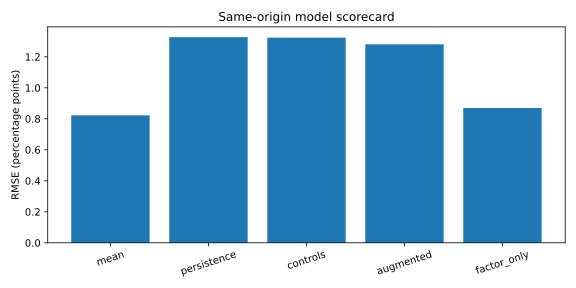

In [16]:
display(SVG(filename=str(ROOT/'figures/05_scorecard.svg')))

## 10. Robustness & Placebos

The **1,000-refit 4-quarter block shuffle** preserves within-block signal structure but not a valid exact exchangeable null; report an **exploratory tail fraction**, never an exact p-value. The **2,000-draw paired circular-block bootstrap** retains local serial dependence in OOS error pairs; its interval is descriptive and sensitive to block length and small effective sample. The 1,000 exposure perturbations test a plausible NAICS 493/492 blend, not precise issuer revenue weights.

In [17]:
print('Block shuffle draws:',len(r['null']),'| exploratory tail fraction:',r['summary']['permutation_exploratory_tail_fraction'])
print('Paired bootstrap draws:',len(r['bootstrap']),'| 95% interval:',r['summary']['bootstrap_95pct_delta_rmse_pp'])
print('Exposure draws:',len(r['perturb']),'| control-relative positive fraction:',r['summary']['exposure_positive_fraction'])

Block shuffle draws: 1000 | exploratory tail fraction: 0.059940059940059943
Paired bootstrap draws: 2000 | 95% interval: [-0.04227434872700144, 0.10799229213237661]
Exposure draws: 1000 | control-relative positive fraction: 1.0


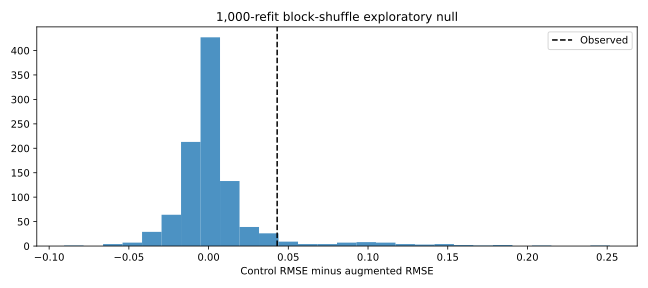

In [18]:
display(SVG(filename=str(ROOT/'figures/06_block_placebo.svg')))

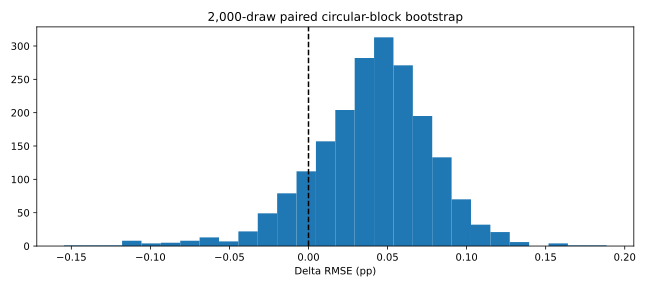

In [19]:
display(SVG(filename=str(ROOT/'figures/07_bootstrap.svg')))

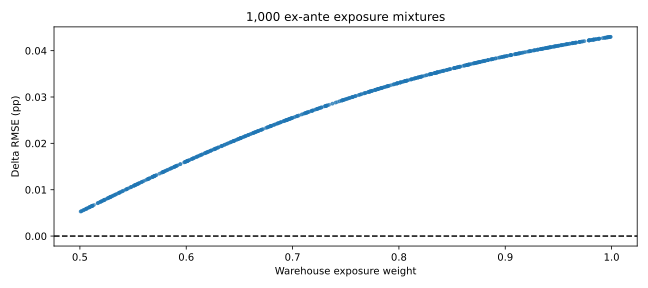

In [20]:
display(SVG(filename=str(ROOT/'figures/08_exposure.svg')))

In [21]:
display(r['ablations'].round(5))
display(r['horizons'].round(5))
display(r['lags'].round(5))

,ablation,n_oos,delta_rmse_pp
0,no_share_level,57,0.02674
1,no_courier,57,-0.00955
2,no_macro,57,-0.02462


,horizon_quarters,n_oos,delta_rmse_pp
0,1,59,0.04007
1,2,57,0.04301
2,4,53,0.11889


,payroll_lag_quarters,n_oos,delta_rmse_pp
0,1,57,0.04301
1,2,56,0.03403
2,3,55,0.09470


## 11. Regime Sensitivity

The positive aggregate control-relative RMSE gain is concentrated in **2020–2021**. Before 2020, after 2021 and after excluding 2020–2021, the incremental gain is **negative**. Pandemic shocks and the 2025 Census definition/benchmark change prevent treating the full-sample coefficient as stationary.

In [22]:
display(r['regimes'].round(5))
assert r['regimes'].set_index('regime').loc['exclude_2020_2021','delta_rmse_pp']<0

,regime,n,delta_rmse_pp,rmse_controls,rmse_augmented
0,pre_2020,33,-0.00365,0.81929,0.82294
1,2020_2021,8,0.15633,3.08235,2.92602
2,post_2021,16,-0.08065,0.32151,0.40217
3,exclude_2020_2021,49,-0.01638,0.69700,0.71338


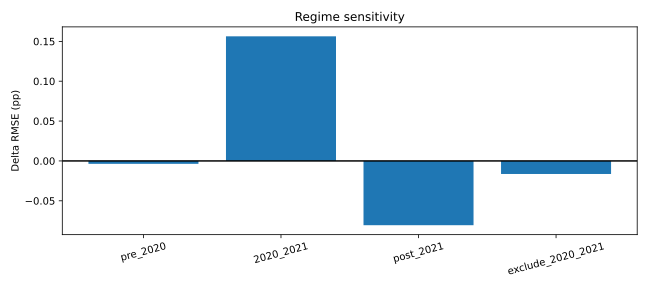

In [23]:
display(SVG(filename=str(ROOT/'figures/09_regimes.svg')))

In [24]:
display(r['loo'].round(5))

,excluded_year,n_remaining,delta_rmse_pp
0,2011,56,0.04339
1,2012,53,0.04463
2,2013,53,0.04460
3,2014,53,0.04464
4,2015,53,0.04458
5,2016,53,0.04452
6,2017,53,0.04453
7,2018,53,0.04480
8,2019,53,0.05230
9,2020,53,0.04619


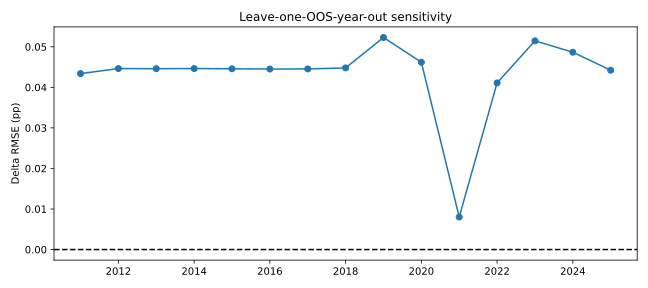

In [25]:
display(SVG(filename=str(ROOT/'figures/10_leave_one_year_out.svg')))

## 12. Bias Audit & Verdict

**PIT/revisions:** exact historical Census/BLS vintages not retrieved; lagged revised snapshots remain non-PIT. **Lookahead:** no future feature values or full-sample scaling in the model, and three-origin purge applies. **Selection:** reverse-direction hypothesis is not independent of prior warehousing research; no preregistered prospective holdout. **Survivorship:** no issuer sample, but the national survey has coverage/definition changes. **Overlap:** two-quarter targets and serial errors make IID inference invalid. **Multiple testing:** exploratory robustness does not license selecting the best horizon after seeing the outcomes. **Costs:** no tradable securities, corporate fundamentals, benchmark-adjusted returns or execution costs. **Verdict:** negative/unstable macro factor, no investable alpha.

In [26]:
s=r['summary']
checks={'loses_to_mean':float(r['scorecard'].set_index('model').loc['augmented','rmse_pp'])>float(r['scorecard'].set_index('model').loc['mean','rmse_pp']),
'bootstrap_crosses_zero':s['bootstrap_95pct_delta_rmse_pp'][0]<0<s['bootstrap_95pct_delta_rmse_pp'][1],
'nonpandemic_negative':float(r['regimes'].set_index('regime').loc['exclude_2020_2021','delta_rmse_pp'])<0,
'PIT_unverified':not s['PIT_verified'],'equity_unverified':not s['equity_returns_tested']}
display(pd.Series(checks,name='Audit result'))
assert all(checks.values())

loses_to_mean             True
bootstrap_crosses_zero    True
nonpandemic_negative      True
PIT_unverified            True
equity_unverified         True
Name: Audit result, dtype: bool

## 13. Reproduction

Reproduction from a clean directory: `pip install -r requirements.txt`; `OPENBLAS_NUM_THREADS=1 python run_analysis.py`; `PYTHONPATH=. OPENBLAS_NUM_THREADS=1 pytest -q tests`; `jupyter nbconvert --to notebook --execute research.ipynb --output reproduced.ipynb`. The original 107-row raw file is immutable and hash checked. All model tables, 1,000 permutations, 2,000 bootstrap draws and 1,000 exposure mixtures are recomputed from it. The root repository's `scripts/validate_studies.py` is a **layout** check, not a numerical CI run.

In [27]:
print('Frozen SHA:',s['source_snapshot_sha256'])
print('Observed rows:',s['raw_rows'],'| formation rows:',s['formation_rows'],'| OOS:',s['oos_rows'])
print('Figure files:',sorted(x.name for x in (ROOT/'figures').glob('*.svg')))

Frozen SHA: 17b99d105505b7c4ef7741012cf65d916bac0b907403474f18cffedcc4a99b2d
Observed rows: 107 | formation rows: 99 | OOS: 57
Figure files: ['01_retail_share.svg', '02_capacity_factor.svg', '03_scatter.svg', '04_oos_predictions.svg', '05_scorecard.svg', '06_block_placebo.svg', '07_bootstrap.svg', '08_exposure.svg', '09_regimes.svg', '10_leave_one_year_out.svg']


## 14. Next-Stage Protocol

Acquire true 2000–2026 Census quarterly vintages and BLS monthly release histories (ALFRED or official archived releases); reproduce the historical 2025 methodology break; source independently dated U.S. retailer digital sales and 10-Q/10-K disclosures. Establish issuer-level exposures before any leave-one-company-out test. Only then preregister a 2027-forward holdout with dividend-adjusted total returns, industry controls, realistic publication dates, transaction costs, and multiple-testing correction. **Do not relabel this macro pilot as equity alpha.**

In [28]:
pending=pd.DataFrame({'required_next_stage':['Census/BLS historical release vintages','2025 Census definition bridge','Issuer-level dated e-commerce sales','Delisted-inclusive total-return panel','Costs and execution model'], 'status':['NOT RETRIEVED']*5})
display(pending)

,required_next_stage,status
0,Census/BLS historical release vintages,NOT RETRIEVED
1,2025 Census definition bridge,NOT RETRIEVED
2,Issuer-level dated e-commerce sales,NOT RETRIEVED
3,Delisted-inclusive total-return panel,NOT RETRIEVED
4,Costs and execution model,NOT RETRIEVED


## 15. Sources & Artifacts

**Official data:** [ECOMPCTSA](https://fred.stlouisfed.org/series/ECOMPCTSA), [CES4349300001](https://fred.stlouisfed.org/series/CES4349300001), [CES4349200001](https://fred.stlouisfed.org/series/CES4349200001), [PAYEMS](https://fred.stlouisfed.org/series/PAYEMS); see `data/source_register.csv` for source grades, release dates, observation ranges, revision caveats, and exact URLs. **Artifacts:** raw snapshot, derived panel, source and exposure registers, 11 computed result files, 10 SVG diagnostics, Python modules, tests and logs. **No claim of issuer-level equity returns or actual-vintage point-in-time availability.**

In [29]:
print('Verdict: FAIL as robust incremental retail-share predictor; reproduced retrospective macro pilot only.')
print('PIT:',s['PIT_verified'],'| issuer fundamentals:',s['firm_fundamentals_tested'],'| equity returns:',s['equity_returns_tested'])

Verdict: FAIL as robust incremental retail-share predictor; reproduced retrospective macro pilot only.
PIT: False | issuer fundamentals: False | equity returns: False
